# 03 共同学習率 0.2 と 0.3（40往復、local step 8）

このNotebookが答える問いは1つである。

同じ初期状態、40往復、各 pair 8回更新という条件で、共同学習率 0.2 と 0.3 のどちらがよいか。

TT pair の結合テンソル `T` と通常 parameter は、各条件の中で同じ学習率を使って同時に更新する。この2条件の差から、学習率一般の最適値、別モデルでの最適値、TT更新だけの効果は結論しない。

初期状態は 01 の `initial_stage_c.pt` を、条件ごとに読み直す。02 が保存した学習結果は、更新予算が違う参考値として読むだけで、03 の結果には数えない。02 の Notebook、モデル、CSV、JSON、PNG は変更しない。

本実験は `RUN_MAIN_EXPERIMENT = False` が既定である。False のままでは 40 往復を開始しない。smoke は別ディレクトリで、本実験の完了ではない。


## 1. 設定

共同学習率は、TT pair と通常 parameter の両方に同じ値を使う。候補は 0.2 と 0.3 だけである。

6 core の1往復は 10 pair 訪問である。各 pair で局所更新を $L=8$ 回行うと、正常な1往復の成功更新数は $10L=80$ である。40往復を完了すると

$$
U=10\times 40\times 8=3200
$$

回の全データ勾配になる。2条件の合計は 6,400 回である。

early stopping は無効にする。非有限な損失・勾配・更新候補、または SVD の数値失敗のときだけ、その条件を途中終了にする。失敗した候補は commit しない。final は予算終了時のモデル、途中終了のときは最後の正常状態である。best は往復終了時の validation loss の最小で、初期状態も含む。validation は開発用であり、test と rank-selection 用の分割は走査しない。

02 の学習率 0.1、20往復、local step 4 は更新回数が 800 であり、この 3,200 回とは予算が違う。学習率だけを変えた比較としては読まない。


In [7]:
import csv
import hashlib
import json
import math
import os
import statistics
import struct
import subprocess
import sys
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import torch
from matplotlib import font_manager
from torch import nn
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import TTLinear
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    split_fashion_mnist_dataset,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import (
    evaluate,
    load_condition_summary,
    load_tt_linear_sweep_checkpoint,
    run_resumable_condition_grid,
    save_tt_linear_full_batch_sweep_run,
    train_tt_linear_full_batch_sweeps,
)
from nn_compression.tt_mps import tt_matrix_canonicality_errors
from nn_compression.utils import find_project_root, get_experiment_dirs, set_seed

# 本実験の2条件は、このスイッチが True のときだけ開始する。
RUN_MAIN_EXPERIMENT = True
# 学習率 0.2 と 0.3 の短い確認。本実験とは別ディレクトリへ書く。
RUN_SMOKE = False

SEED = 0
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
RANK_CAP = 12
EXPECTED_INITIAL_RANKS = (1, 8, 12, 12, 12, 12, 1)
LAYER_NAME = "fc1"
BATCH_SIZE = 512
DIAGNOSTIC_BATCH_SIZE = 512
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
JOINT_LEARNING_RATES = [0.2, 0.3]
MAX_SWEEPS = 40
LOCAL_STEPS_PER_PAIR = 8
SMOKE_MAX_SWEEPS = 1
SMOKE_LOCAL_STEPS = 1
EARLY_STOPPING_PATIENCE = 1
EARLY_STOPPING_MIN_DELTA = 0.0
EARLY_STOPPING_ENABLED = False
EXPERIMENT_NAME = "03_joint_learning_rate_02_03_s40_l8"
SMOKE_NAME = "03_joint_learning_rate_02_03_s40_l8_smoke"
PROTECTED_EXPERIMENT_NAMES = {
    "00_full_batch_two_core_sweep_training",
    "01_tt_initialization_scale_diagnostics",
    "02_full_batch_sweep_update_budget_grid",
    "02_full_batch_sweep_update_budget_grid_smoke",
    "02_full_batch_sweep_update_budget_grid_smoke_bs512",
}

assert math.prod(OUT_MODES) == 512
assert math.prod(IN_MODES) == 784
assert len(OUT_MODES) == 6
assert JOINT_LEARNING_RATES == [0.2, 0.3]
assert MAX_SWEEPS == 40
assert LOCAL_STEPS_PER_PAIR == 8
assert BATCH_SIZE == 512
assert 10 * LOCAL_STEPS_PER_PAIR == 80
assert 10 * MAX_SWEEPS * LOCAL_STEPS_PER_PAIR == 3200
assert len(JOINT_LEARNING_RATES) * 3200 == 6400
assert EXPERIMENT_NAME not in PROTECTED_EXPERIMENT_NAMES
assert SMOKE_NAME not in PROTECTED_EXPERIMENT_NAMES
assert EXPERIMENT_NAME.startswith("03_")
assert SMOKE_NAME.startswith("03_")

project_root = find_project_root(Path.cwd())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INITIAL_CHECKPOINT = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "01_tt_initialization_scale_diagnostics"
    / "initial_stage_c.pt"
)
REFERENCE_SUMMARY = (
    project_root
    / "results"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "02_full_batch_sweep_update_budget_grid"
    / "condition_summary.csv"
)
_, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "40_dmrg",
    "10_fashion_mnist_mlp",
    EXPERIMENT_NAME,
)
_, smoke_models_dir, smoke_results_dir = get_experiment_dirs(
    project_root,
    "40_dmrg",
    "10_fashion_mnist_mlp",
    SMOKE_NAME,
)
output_dirs = (models_dir, results_dir, smoke_models_dir, smoke_results_dir)
for directory in output_dirs:
    if directory.name in PROTECTED_EXPERIMENT_NAMES:
        raise RuntimeError(f"02 の保存先へ書き込もうとしました: {directory}")
if len({directory.resolve() for directory in output_dirs}) != 4:
    raise RuntimeError("本実験と smoke の保存先が重なっています。")

for font_name in ("Yu Gothic", "Meiryo", "MS Gothic", "Noto Sans CJK JP"):
    if any(font.name == font_name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break

print("device:", DEVICE)
print("dtype: torch.float32（MNISTMLP と checkpoint の想定）")
print("RUN_MAIN_EXPERIMENT:", RUN_MAIN_EXPERIMENT)
print("RUN_SMOKE:", RUN_SMOKE)
print("batch size:", BATCH_SIZE)
print("initial checkpoint:", INITIAL_CHECKPOINT)
print("main models:", models_dir)
print("smoke models:", smoke_models_dir)


device: cuda
dtype: torch.float32（MNISTMLP と checkpoint の想定）
RUN_MAIN_EXPERIMENT: True
RUN_SMOKE: False
batch size: 512
initial checkpoint: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\01_tt_initialization_scale_diagnostics\initial_stage_c.pt
main models: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\03_joint_learning_rate_02_03_s40_l8
smoke models: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\03_joint_learning_rate_02_03_s40_l8_smoke


## 2. データと共通初期状態

前処理は `ToTensor` だけ、分割は seed 0 の 50,000 / 5,000 / 5,000 である。minibatch は全学習データの平均勾配を分割して足すために使い、minibatch ごとに parameter は更新しない。

モデルの骨格は checkpoint の core から作る。seed から TT-SVD をやり直して初期重みにはしない。ファイルが無い場合、または modes、rank、中心、tensor 値が合わない場合は、ここで止める。各条件は、この同じファイルから独立に読み直す。


In [8]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def condition_id(learning_rate, max_sweeps, local_steps):
    rate = f"{float(learning_rate):.1f}".replace(".", "p")
    return f"lr{rate}_s{int(max_sweeps)}_l{int(local_steps)}"


MAIN_CONDITION_IDS = [
    condition_id(learning_rate, MAX_SWEEPS, LOCAL_STEPS_PER_PAIR)
    for learning_rate in JOINT_LEARNING_RATES
]
SMOKE_CONDITION_IDS = [
    condition_id(learning_rate, SMOKE_MAX_SWEEPS, SMOKE_LOCAL_STEPS)
    for learning_rate in JOINT_LEARNING_RATES
]
assert MAIN_CONDITION_IDS == ["lr0p2_s40_l8", "lr0p3_s40_l8"]
assert SMOKE_CONDITION_IDS == ["lr0p2_s1_l1", "lr0p3_s1_l1"]
assert set(MAIN_CONDITION_IDS).isdisjoint(SMOKE_CONDITION_IDS)

if not INITIAL_CHECKPOINT.is_file():
    raise FileNotFoundError(
        "共通初期 checkpoint がありません。初期化し直さずに停止します: "
        f"{INITIAL_CHECKPOINT}"
    )
SHARED_CHECKPOINT_SHA256 = file_sha256(INITIAL_CHECKPOINT)

fashion_root = project_root / "data" / "FashionMNIST" / "raw"
required_files = [
    "train-images-idx3-ubyte",
    "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte",
    "t10k-labels-idx1-ubyte",
]
missing_files = [name for name in required_files if not (fashion_root / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        "Fashion-MNIST がありません。代替データでは実行しません: " + ", ".join(missing_files)
    )

set_seed(SEED)
full_train, test_dataset = get_fashion_mnist_datasets(
    project_root / "data",
    download=False,
)
train_dataset, early_stopping_dataset, rank_selection_dataset = split_fashion_mnist_dataset(
    full_train,
    SPLIT_LENGTHS,
    seed=SEED,
)
gradient_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)
validation_loader = DataLoader(
    early_stopping_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)
diagnostic_images = torch.stack(
    [train_dataset[index][0] for index in range(DIAGNOSTIC_BATCH_SIZE)]
)
diagnostic_labels = torch.tensor(
    [int(train_dataset[index][1]) for index in range(DIAGNOSTIC_BATCH_SIZE)],
    dtype=torch.long,
)
criterion = nn.CrossEntropyLoss()


def _subset_identity(subset):
    indices = [int(index) for index in subset.indices]
    digest = hashlib.sha256()
    for index in indices:
        digest.update(struct.pack("<q", index))
    return {
        "n": len(indices),
        "head": indices[:5],
        "tail": indices[-5:],
        "sha256": digest.hexdigest(),
    }


SPLIT_IDENTITY = {
    "train": _subset_identity(train_dataset),
    "early_stopping_validation": _subset_identity(early_stopping_dataset),
    "rank_selection_validation": _subset_identity(rank_selection_dataset),
}
SPLIT_INDEX_SHA256 = "|".join(
    SPLIT_IDENTITY[name]["sha256"]
    for name in ("train", "early_stopping_validation", "rank_selection_validation")
)
TRAINING_MODULE_PATH = Path(train_tt_linear_full_batch_sweeps.__code__.co_filename).resolve()
TRAINING_MODULE_SHA256 = file_sha256(TRAINING_MODULE_PATH)
try:
    GIT_HEAD = subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=project_root,
        text=True,
    ).strip()
except (OSError, subprocess.CalledProcessError):
    GIT_HEAD = "unavailable"

print(
    "train / early-stopping validation / rank-selection:",
    len(train_dataset),
    len(early_stopping_dataset),
    len(rank_selection_dataset),
)
print("test is not scanned:", len(test_dataset))
print("rank-selection validation is not scanned:", len(rank_selection_dataset))
print("diagnostic batch:", tuple(diagnostic_images.shape))
print("checkpoint sha256:", SHARED_CHECKPOINT_SHA256)
print("split index sha256:", SPLIT_INDEX_SHA256)
print("training module:", TRAINING_MODULE_PATH)
print("training module sha256:", TRAINING_MODULE_SHA256)
print("git head:", GIT_HEAD)


def _core_keys(state):
    prefix = f"{LAYER_NAME}.cores."
    return sorted(
        (key for key in state if key.startswith(prefix)),
        key=lambda key: int(key.rsplit(".", 1)[-1]),
    )


def assert_checkpoint_contract(payload):
    if payload.get("layer_name") != LAYER_NAME:
        raise ValueError(f"layer_name が一致しません: {payload.get('layer_name')!r}")
    if tuple(payload.get("out_modes", ())) != OUT_MODES:
        raise ValueError(f"out_modes が一致しません: {payload.get('out_modes')!r}")
    if tuple(payload.get("in_modes", ())) != IN_MODES:
        raise ValueError(f"in_modes が一致しません: {payload.get('in_modes')!r}")
    if int(payload.get("rank_cap", -1)) != RANK_CAP:
        raise ValueError(f"rank_cap が一致しません: {payload.get('rank_cap')!r}")
    if int(payload.get("canonical_center", -1)) != 0:
        raise ValueError(
            f"canonical_center は 0 である必要があります: {payload.get('canonical_center')!r}"
        )
    if payload.get("stage") != "C":
        raise ValueError(f"stage C ではありません: {payload.get('stage')!r}")
    if int(payload.get("seed", -1)) != SEED:
        raise ValueError(f"seed が一致しません: {payload.get('seed')!r}")


def build_model_from_checkpoint(path):
    payload = torch.load(Path(path), map_location="cpu", weights_only=False)
    assert_checkpoint_contract(payload)
    state = payload["state_dict"]
    keys = _core_keys(state)
    if len(keys) != len(OUT_MODES):
        raise ValueError(f"core 数が一致しません: {len(keys)}")
    cores = [state[key].detach().to(dtype=torch.float32, device="cpu") for key in keys]
    ranks = (int(cores[0].shape[0]),) + tuple(int(core.shape[-1]) for core in cores)
    if ranks != EXPECTED_INITIAL_RANKS:
        raise ValueError(f"初期 rank 列が一致しません: {ranks}")
    errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, 0)
    if errors["left"]:
        raise ValueError("site 0 正準のはずが、左側の直交誤差があります。")
    ortho_error = max(float(item) for item in errors["right"])
    if ortho_error > 1e-4:
        raise ValueError(f"site 0 の右直交誤差が大きすぎます: {ortho_error}")
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state[f"{LAYER_NAME}.bias"].detach())
    own = dict(model.named_parameters())
    if set(own) != set(state):
        raise ValueError(
            "checkpoint とモデルの parameter 名が一致しません: "
            f"extra={sorted(set(own) - set(state))} missing={sorted(set(state) - set(own))}"
        )
    with torch.no_grad():
        for key, value in state.items():
            if key.startswith(f"{LAYER_NAME}.cores.") or key == f"{LAYER_NAME}.bias":
                continue
            own[key].copy_(value)
    loaded = model.state_dict()
    for key, value in state.items():
        if loaded[key].dtype != torch.float32:
            raise TypeError(f"{key} の dtype が float32 ではありません: {loaded[key].dtype}")
        if not torch.equal(loaded[key].cpu(), value.detach().to(dtype=torch.float32, device="cpu")):
            raise ValueError(f"初期 state が checkpoint と一致しません: {key}")
    model.to(DEVICE)
    for core in model.fc1.cores:
        core.requires_grad_(False)
    moved = model.state_dict()
    for key, value in state.items():
        target = value.detach().to(dtype=torch.float32, device=DEVICE)
        if not torch.equal(moved[key], target):
            raise ValueError(f"device へ移した初期 state が checkpoint と一致しません: {key}")
    return model, ortho_error


probe_model, initial_ortho_error = build_model_from_checkpoint(INITIAL_CHECKPOINT)
if file_sha256(INITIAL_CHECKPOINT) != SHARED_CHECKPOINT_SHA256:
    raise RuntimeError("checkpoint を読んだだけで共通ファイルの内容が変わりました。")
print("initial ranks:", EXPECTED_INITIAL_RANKS)
print("site-0 right orthogonality max error:", initial_ortho_error)
print(
    "module:",
    type(probe_model.fc1).__name__,
    type(probe_model.fc2).__name__,
    type(probe_model.fc3).__name__,
)
del probe_model


train / early-stopping validation / rank-selection: 50000 5000 5000
test is not scanned: 10000
rank-selection validation is not scanned: 5000
diagnostic batch: (512, 1, 28, 28)
checkpoint sha256: ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd506f5a348ae38ce10c6a
split index sha256: aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26
training module: D:\dev\nn-compression-svd-dmrg\src\nn_compression\training\tt_linear_full_batch_sweep.py
training module sha256: 82f01f70fa227e73f63d0007891584372354f85e2b82a33455281730fa015cf2
git head: 95d5fe44b71d6f6fbd56e8fda9713b85983ea138
initial ranks: (1, 8, 12, 12, 12, 12, 1)
site-0 right orthogonality max error: 9.382572443428217e-07
module: TTLinear Linear Linear


## 3. 1条件の実行

各条件は `initial_stage_c.pt` からモデルを作り直す。前の条件の重み、履歴、best、更新回数は渡さない。

1回の局所更新は `train_tt_linear_full_batch_sweeps` が行う。最新の pair から `T` を作り、全学習データの平均 cross-entropy の勾配を計算し、`T` と通常 parameter を同じ学習率で更新する。進行方向に応じた SVD と rank 上限のあと、検証に通った候補だけを commit する。同じ pair を繰り返すときも、毎 step で core から `T` を作り、勾配を計算し直す。momentum、Adam、weight decay は使わない。

正常完了した往復の成功更新数は `10L` である。40往復を完了した条件は 3,200 回になる。途中終了の往復は完了数に入れない。final と best は別ファイルへ保存し、読み戻した validation が保存時の値から離れていないことを確認する。

条件が終わるたびに、集計 CSV を同じディレクトリの一時ファイルへ書いてから置き換える。再開時は condition ID に加えて、学習率、往復数、local step、batch size、checkpoint の SHA-256、分割、学習コードの識別子が一致するときだけスキップする。


In [9]:
SUMMARY_FIELDS = [
    "condition_id",
    "status",
    "joint_learning_rate",
    "tt_pair_learning_rate",
    "dense_parameter_learning_rate",
    "max_sweeps",
    "local_steps_per_pair",
    "batch_size",
    "requested_full_data_gradient_passes",
    "completed_sweeps",
    "successful_local_updates",
    "incomplete_sweep_successes",
    "stop_reason",
    "stop_detail",
    "stop_sweep",
    "stop_pair",
    "stop_direction",
    "stop_local_step",
    "initial_train_loss",
    "initial_train_acc",
    "initial_validation_loss",
    "initial_validation_acc",
    "final_train_loss",
    "final_train_acc",
    "final_validation_loss",
    "final_validation_acc",
    "final_is_completed_budget",
    "best_sweep",
    "best_train_loss",
    "best_train_acc",
    "best_validation_loss",
    "best_validation_acc",
    "seconds_load",
    "seconds_train",
    "seconds_save",
    "seconds_total",
    "timing_window",
    "checkpoint_sha256",
    "checkpoint_path",
    "code_sha256",
    "code_path",
    "git_head",
    "split_index_sha256",
    "out_modes",
    "in_modes",
    "rank_cap",
    "seed",
    "max_tt_relative_update",
    "max_dense_relative_update",
    "reloaded_final_validation_loss",
    "reloaded_final_validation_acc",
    "reloaded_best_validation_loss",
    "reloaded_best_validation_acc",
]
GRID_SETTING_FIELDS = (
    "joint_learning_rate",
    "tt_pair_learning_rate",
    "dense_parameter_learning_rate",
    "max_sweeps",
    "local_steps_per_pair",
    "batch_size",
    "checkpoint_sha256",
    "code_sha256",
    "split_index_sha256",
)


def _history_row(result, sweep):
    matches = [row for row in result.history if int(row["sweep"]) == sweep]
    if len(matches) != 1:
        raise RuntimeError(f"sweep {sweep} の評価行が一意ではありません。")
    return matches[0]


def _finite_metric(value, name):
    number = float(value)
    if not math.isfinite(number):
        raise ValueError(f"{name} が有限ではありません: {number}")
    return number


def _spec(learning_rate, max_sweeps, local_steps):
    rate = float(learning_rate)
    return {
        "condition_id": condition_id(rate, max_sweeps, local_steps),
        "joint_learning_rate": rate,
        "tt_pair_learning_rate": rate,
        "dense_parameter_learning_rate": rate,
        "max_sweeps": int(max_sweeps),
        "local_steps_per_pair": int(local_steps),
        "batch_size": BATCH_SIZE,
        "checkpoint_sha256": SHARED_CHECKPOINT_SHA256,
        "code_sha256": TRAINING_MODULE_SHA256,
        "split_index_sha256": SPLIT_INDEX_SHA256,
    }


def run_condition(spec, output_models):
    label = spec["condition_id"]
    learning_rate = float(spec["joint_learning_rate"])
    max_sweeps = int(spec["max_sweeps"])
    local_steps = int(spec["local_steps_per_pair"])
    if learning_rate not in JOINT_LEARNING_RATES:
        raise ValueError(f"今回の学習率ではありません: {learning_rate}")
    if float(spec["tt_pair_learning_rate"]) != learning_rate:
        raise ValueError("TT pair の学習率が共同学習率と違います。")
    if float(spec["dense_parameter_learning_rate"]) != learning_rate:
        raise ValueError("通常 parameter の学習率が共同学習率と違います。")
    directory = Path(output_models) / label
    if directory.exists() and any(directory.iterdir()):
        raise FileExistsError(f"既存結果があるため上書きしません: {directory}")
    if file_sha256(INITIAL_CHECKPOINT) != SHARED_CHECKPOINT_SHA256:
        raise RuntimeError("学習前に共通 checkpoint の内容が変わっています。")

    synchronize()
    started = time.perf_counter()
    model, _ortho_error = build_model_from_checkpoint(INITIAL_CHECKPOINT)
    synchronize()
    loaded = time.perf_counter()
    result = train_tt_linear_full_batch_sweeps(
        model,
        gradient_loader,
        train_eval_loader,
        validation_loader,
        layer_name=LAYER_NAME,
        rank_cap=RANK_CAP,
        tt_pair_learning_rate=learning_rate,
        dense_parameter_learning_rate=learning_rate,
        max_sweeps=max_sweeps,
        local_steps_per_pair=local_steps,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
        early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
        early_stopping_enabled=EARLY_STOPPING_ENABLED,
        diagnostic_images=diagnostic_images,
        diagnostic_labels=diagnostic_labels,
        device=DEVICE,
        center=0,
        criterion=criterion,
    )
    synchronize()
    trained = time.perf_counter()
    if result.stop_reason == "early_stopping":
        raise RuntimeError("early stopping を無効化したのに early_stopping で止まりました。")
    if result.stop_reason not in {"max_sweeps", "non_finite", "svd_failure"}:
        raise RuntimeError(f"想定していない停止理由です: {result.stop_reason}")

    completed_budget = (
        result.stop_reason == "max_sweeps" and result.completed_sweeps == max_sweeps
    )
    if completed_budget:
        updates_per_sweep = 10 * local_steps
        expected_updates = updates_per_sweep * max_sweeps
        if local_steps == LOCAL_STEPS_PER_PAIR and updates_per_sweep != 80:
            raise RuntimeError(f"local step 8 の1往復は 80 更新である必要があります: {updates_per_sweep}")
        if max_sweeps == MAX_SWEEPS and expected_updates != 3200:
            raise RuntimeError(f"40往復の成功更新数は 3,200 である必要があります: {expected_updates}")
        if result.successful_local_updates != expected_updates:
            raise RuntimeError(
                f"{label} の成功更新数が {expected_updates} ではありません: "
                f"{result.successful_local_updates}"
            )
        ordered = sorted(result.history, key=lambda item: int(item["sweep"]))
        if [int(item["sweep"]) for item in ordered] != list(range(max_sweeps + 1)):
            raise RuntimeError(f"{label} の往復履歴が 0 から {max_sweeps} まで揃っていません。")
        for previous, current in zip(ordered, ordered[1:]):
            delta = int(current["cumulative_successful_updates"]) - int(
                previous["cumulative_successful_updates"]
            )
            if delta != updates_per_sweep:
                raise RuntimeError(
                    f"{label} の往復 {int(current['sweep'])} の成功更新数が "
                    f"{updates_per_sweep} ではありません: {delta}"
                )
            if int(current["center"]) != 0:
                raise RuntimeError(
                    f"{label} の往復 {int(current['sweep'])} の中心が site 0 ではありません。"
                )
        if result.center != 0:
            raise RuntimeError(f"{label} の完了後の中心が site 0 ではありません: {result.center}")
        status = "正常完了"
    else:
        if result.stop_reason == "max_sweeps":
            raise RuntimeError("最大往復数まで到達した記録と完了数が一致しません。")
        status = "途中終了"
    initial = _history_row(result, 0)
    best = _history_row(result, result.best_sweep)

    config = {
        "notebook": "03_joint_learning_rate_02_03_s40_l8.ipynb",
        "model": "MNISTMLP fc1 TTLinear, fc2 Linear, fc3 Linear, ReLU",
        "condition_id": label,
        "initialization": "01 initial_stage_c.pt reloaded for every condition",
        "checkpoint_path": str(INITIAL_CHECKPOINT),
        "checkpoint_sha256": SHARED_CHECKPOINT_SHA256,
        "layer_name": LAYER_NAME,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "rank_cap": RANK_CAP,
        "expected_initial_ranks": list(EXPECTED_INITIAL_RANKS),
        "seed": SEED,
        "dtype": "torch.float32",
        "batch_size": BATCH_SIZE,
        "joint_learning_rate": learning_rate,
        "tt_pair_learning_rate": learning_rate,
        "dense_parameter_learning_rate": learning_rate,
        "learning_rates_are_tied_for_this_comparison": True,
        "max_sweeps": max_sweeps,
        "local_steps_per_pair": local_steps,
        "requested_full_data_gradient_passes": 10 * local_steps * max_sweeps,
        "early_stopping_enabled": EARLY_STOPPING_ENABLED,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
        "split": "Fashion-MNIST 50000/5000/5000 seed 0; train / early-stopping / rank-selection",
        "split_identity": SPLIT_IDENTITY,
        "split_index_sha256": SPLIT_INDEX_SHA256,
        "test_and_rank_selection_are_not_scanned": True,
        "update_targets": "merged pair T, fc1.bias, fc2, fc3",
        "code_path": str(TRAINING_MODULE_PATH),
        "code_sha256": TRAINING_MODULE_SHA256,
        "git_head": GIT_HEAD,
    }
    save_tt_linear_full_batch_sweep_run(directory, model, result, config)
    synchronize()
    saved = time.perf_counter()
    if file_sha256(INITIAL_CHECKPOINT) != SHARED_CHECKPOINT_SHA256:
        raise RuntimeError("学習または保存のあと、共通 checkpoint の内容が変わりました。")
    if completed_budget:
        final_metrics = _history_row(result, max_sweeps)
    else:
        retained_train_loss, retained_train_acc = evaluate(
            model, train_eval_loader, criterion, DEVICE
        )
        retained_validation_loss, retained_validation_acc = evaluate(
            model, validation_loader, criterion, DEVICE
        )
        final_metrics = {
            "train_loss": retained_train_loss,
            "train_acc": retained_train_acc,
            "validation_loss": retained_validation_loss,
            "validation_acc": retained_validation_acc,
        }

    saved_initial = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
    shared = torch.load(INITIAL_CHECKPOINT, map_location="cpu", weights_only=False)
    for key, value in shared["state_dict"].items():
        current = saved_initial["state_dict"][key]
        reference = value.detach().to(dtype=current.dtype, device="cpu")
        if not torch.equal(current.cpu(), reference):
            raise RuntimeError(f"保存した初期 state が共通 checkpoint と一致しません: {key}")

    final_model = build_model_from_checkpoint(INITIAL_CHECKPOINT)[0]
    load_tt_linear_sweep_checkpoint(directory / "final_model.pt", final_model)
    final_model.to(DEVICE)
    for key, value in model.state_dict().items():
        if not torch.equal(final_model.state_dict()[key], value):
            raise RuntimeError(f"final checkpoint の再読込が学習後 state と一致しません: {key}")
    reloaded_validation_loss, reloaded_validation_acc = evaluate(
        final_model, validation_loader, criterion, DEVICE
    )
    best_model = build_model_from_checkpoint(INITIAL_CHECKPOINT)[0]
    load_tt_linear_sweep_checkpoint(directory / "best_model.pt", best_model)
    best_model.to(DEVICE)
    reloaded_best_loss, reloaded_best_acc = evaluate(
        best_model, validation_loader, criterion, DEVICE
    )

    ok_logs = [row for row in result.local_updates if row["status"] == "ok"]
    tt_rel = [float(row["tt_relative_update"]) for row in ok_logs]
    dense_rel = [float(row["dense_relative_update"]) for row in ok_logs]
    if any(not math.isfinite(value) for value in tt_rel + dense_rel):
        raise RuntimeError(f"{label} の相対更新量に非有限値があります。")
    row = {
        "condition_id": label,
        "status": status,
        "joint_learning_rate": learning_rate,
        "tt_pair_learning_rate": learning_rate,
        "dense_parameter_learning_rate": learning_rate,
        "max_sweeps": max_sweeps,
        "local_steps_per_pair": local_steps,
        "batch_size": BATCH_SIZE,
        "requested_full_data_gradient_passes": 10 * local_steps * max_sweeps,
        "completed_sweeps": result.completed_sweeps,
        "successful_local_updates": result.successful_local_updates,
        "incomplete_sweep_successes": result.incomplete_sweep_successes,
        "stop_reason": result.stop_reason,
        "stop_detail": result.stop_detail.replace("\n", " "),
        "stop_sweep": result.stop_sweep,
        "stop_pair": result.stop_pair,
        "stop_direction": result.stop_direction,
        "stop_local_step": result.stop_local_step,
        "initial_train_loss": _finite_metric(initial["train_loss"], "initial_train_loss"),
        "initial_train_acc": _finite_metric(initial["train_acc"], "initial_train_acc"),
        "initial_validation_loss": _finite_metric(initial["validation_loss"], "initial_validation_loss"),
        "initial_validation_acc": _finite_metric(initial["validation_acc"], "initial_validation_acc"),
        "final_train_loss": _finite_metric(final_metrics["train_loss"], "final_train_loss"),
        "final_train_acc": _finite_metric(final_metrics["train_acc"], "final_train_acc"),
        "final_validation_loss": _finite_metric(final_metrics["validation_loss"], "final_validation_loss"),
        "final_validation_acc": _finite_metric(final_metrics["validation_acc"], "final_validation_acc"),
        "final_is_completed_budget": completed_budget,
        "best_sweep": result.best_sweep,
        "best_train_loss": _finite_metric(best["train_loss"], "best_train_loss"),
        "best_train_acc": _finite_metric(best["train_acc"], "best_train_acc"),
        "best_validation_loss": _finite_metric(best["validation_loss"], "best_validation_loss"),
        "best_validation_acc": _finite_metric(best["validation_acc"], "best_validation_acc"),
        "seconds_load": loaded - started,
        "seconds_train": trained - loaded,
        "seconds_save": saved - trained,
        "seconds_total": saved - started,
        "timing_window": "cuda synchronize 後の checkpoint 読込、学習（勾配・SVD・往復後評価を含む）、保存。再読込の確認は含まない",
        "checkpoint_sha256": SHARED_CHECKPOINT_SHA256,
        "checkpoint_path": str(INITIAL_CHECKPOINT),
        "code_sha256": TRAINING_MODULE_SHA256,
        "code_path": str(TRAINING_MODULE_PATH),
        "git_head": GIT_HEAD,
        "split_index_sha256": SPLIT_INDEX_SHA256,
        "out_modes": ",".join(str(mode) for mode in OUT_MODES),
        "in_modes": ",".join(str(mode) for mode in IN_MODES),
        "rank_cap": RANK_CAP,
        "seed": SEED,
        "max_tt_relative_update": max(tt_rel) if tt_rel else None,
        "max_dense_relative_update": max(dense_rel) if dense_rel else None,
        "reloaded_final_validation_loss": float(reloaded_validation_loss),
        "reloaded_final_validation_acc": float(reloaded_validation_acc),
        "reloaded_best_validation_loss": float(reloaded_best_loss),
        "reloaded_best_validation_acc": float(reloaded_best_acc),
    }
    final_gap = abs(float(reloaded_validation_loss) - row["final_validation_loss"])
    best_gap = abs(float(reloaded_best_loss) - row["best_validation_loss"])
    print(label, "reload validation gap final/best:", final_gap, best_gap)
    if final_gap > 1e-5 or best_gap > 1e-5:
        raise RuntimeError(f"{label} の再読込後の validation が保存時の指標から離れています。")
    if not math.isfinite(reloaded_validation_loss) or not math.isfinite(reloaded_best_loss):
        raise RuntimeError(f"{label} の再読込後の loss が有限ではありません。")
    print(
        label,
        status,
        "sweeps",
        result.completed_sweeps,
        "/",
        max_sweeps,
        "updates",
        result.successful_local_updates,
        "tt_rel",
        row["max_tt_relative_update"],
        "dense_rel",
        row["max_dense_relative_update"],
        "seconds",
        round(row["seconds_total"], 3),
    )
    return row


def read_history(path):
    with Path(path).open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    for row in rows:
        for key in (
            "sweep",
            "train_loss",
            "train_acc",
            "validation_loss",
            "validation_acc",
            "cumulative_successful_updates",
            "center",
        ):
            row[key] = float(row[key])
    return rows


## 4. smoke run

学習率 0.2 と 0.3 を、それぞれ 1 往復、local step 1 で確認する。1条件の成功更新数は 10 回である。確認するのは、更新の完了、loss と相対更新量の有限性、validation、checkpoint の再読込、実行時間、本実験のおおよその所要時間である。

ここが有限でも、40往復・local step 8 まで安定だとは読まない。評価は往復の終わりに1回なので、local step 8 では勾配計算に対する評価の割合が smoke より小さくなる。

smoke と本実験は別ディレクトリである。`RUN_SMOKE` が False のときは学習を始めない。


In [10]:
def estimate_main_experiment(rows, eval_pair_seconds):
    usable_rows = []
    usable_steps = []
    seen_rates = []
    for row in rows:
        if row["status"] != "正常完了":
            continue
        if int(float(row["max_sweeps"])) != 1 or int(float(row["local_steps_per_pair"])) != 1:
            continue
        if int(float(row["successful_local_updates"])) != 10:
            raise RuntimeError(
                f"{row['condition_id']} は smoke の正常完了なのに成功更新数が 10 ではありません。"
            )
        rate = float(row["joint_learning_rate"])
        if not any(math.isclose(rate, expected, rel_tol=0.0, abs_tol=1e-12) for expected in JOINT_LEARNING_RATES):
            continue
        step_seconds = (float(row["seconds_train"]) - 2.0 * float(eval_pair_seconds)) / 10.0
        usable_rows.append(row)
        usable_steps.append(step_seconds)
        seen_rates.append(rate)
    estimate = {
        "eval_pair_seconds": eval_pair_seconds,
        "grad_step_seconds": usable_steps,
        "conditions": len(JOINT_LEARNING_RATES),
        "updates_per_condition": 3200,
        "includes": "条件ごとの読込・保存の平均、往復終了ごとの評価、局所更新",
    }
    rates_ok = all(
        any(math.isclose(rate, expected, rel_tol=0.0, abs_tol=1e-12) for rate in seen_rates)
        for expected in JOINT_LEARNING_RATES
    )
    if len(usable_rows) != len(JOINT_LEARNING_RATES) or not rates_ok or any(step <= 0 for step in usable_steps):
        estimate["available"] = False
        estimate["reason"] = "0.2 と 0.3 の両方で、局所更新時間を評価時間と分けて取り出せていません。"
        return estimate
    mean_step = statistics.mean(usable_steps)
    mean_load = statistics.mean(float(row["seconds_load"]) for row in usable_rows)
    mean_save = statistics.mean(float(row["seconds_save"]) for row in usable_rows)
    per_condition = (
        mean_load
        + mean_save
        + (MAX_SWEEPS + 1) * eval_pair_seconds
        + 3200 * mean_step
    )
    estimate.update(
        {
            "available": True,
            "mean_grad_step_seconds": mean_step,
            "min_grad_step_seconds": min(usable_steps),
            "max_grad_step_seconds": max(usable_steps),
            "mean_load_seconds": mean_load,
            "mean_save_seconds": mean_save,
            "seconds_per_condition": per_condition,
            "total_seconds": per_condition * len(JOINT_LEARNING_RATES),
            "naive_grad_pass_scaled_train_seconds": statistics.mean(
                float(row["seconds_train"]) for row in usable_rows
            )
            * (3200 / 10)
            * len(JOINT_LEARNING_RATES),
        }
    )
    return estimate


def print_estimate(estimate):
    print("見積もりの前提: smoke の S=1, L=1 で、学習時間から評価2回分を引いた残りを局所更新10回とみなす。")
    print("本実験は S=40, L=8 なので、評価は41回、全データ勾配は3,200回である。")
    print("smoke が有限でも、40往復の安定性は保証しない。")
    if not estimate.get("available"):
        print("内訳見積もりは作れません:", estimate.get("reason"))
        return
    print(
        "評価1組（train 全体と validation）:",
        round(estimate["eval_pair_seconds"], 3),
        "秒",
    )
    print(
        "局所更新1回:",
        round(estimate["mean_grad_step_seconds"], 3),
        "秒（2条件の範囲",
        round(estimate["min_grad_step_seconds"], 3),
        "から",
        round(estimate["max_grad_step_seconds"], 3),
        "）",
    )
    print("2条件の合計見積もり:", round(estimate["total_seconds"] / 60, 2), "分")
    print(
        "参考: smoke の学習時間を、1条件10更新から3,200更新へ伸ばして2条件分にすると",
        round(estimate["naive_grad_pass_scaled_train_seconds"] / 60, 2),
        "分。こちらは L=8 で評価の割合が下がることを反映しない。",
    )


def _run_smoke_or_main(output_models, summary_path, planned):
    return run_resumable_condition_grid(
        planned,
        summary_path=summary_path,
        models_dir=output_models,
        fieldnames=SUMMARY_FIELDS,
        setting_fields=GRID_SETTING_FIELDS,
        run_one=lambda spec: run_condition(spec, output_models),
    )


smoke_summary_path = smoke_results_dir / "condition_summary.csv"
smoke_report_path = smoke_results_dir / "smoke_report.json"
if RUN_SMOKE:
    print("smoke run を実行する。これは本実験2条件ではない。")
    synchronize()
    probe_started = time.perf_counter()
    probe_model, _ortho_error = build_model_from_checkpoint(INITIAL_CHECKPOINT)
    synchronize()
    eval_started = time.perf_counter()
    evaluate(probe_model, train_eval_loader, criterion, DEVICE)
    evaluate(probe_model, validation_loader, criterion, DEVICE)
    synchronize()
    eval_pair_seconds = time.perf_counter() - eval_started
    print("probe load seconds:", round(time.perf_counter() - probe_started - eval_pair_seconds, 3))
    print("probe eval pair seconds:", round(eval_pair_seconds, 3))
    del probe_model
    smoke_rows = _run_smoke_or_main(
        smoke_models_dir,
        smoke_summary_path,
        [_spec(rate, SMOKE_MAX_SWEEPS, SMOKE_LOCAL_STEPS) for rate in JOINT_LEARNING_RATES],
    )
    initial_losses = [float(row["initial_validation_loss"]) for row in smoke_rows]
    print("initial validation loss by condition:", initial_losses)
    if max(initial_losses) - min(initial_losses) != 0:
        print("初期評価値は条件間で一致していない。state の一致確認とは別に記録する。")
    estimate = estimate_main_experiment(smoke_rows, eval_pair_seconds)
    print_estimate(estimate)
    if smoke_report_path.exists():
        print("smoke report は既にあるため上書きしません:", smoke_report_path)
    else:
        smoke_report_path.write_text(
            json.dumps(
                {
                    "kind": "smoke",
                    "is_main_experiment": False,
                    "batch_size": BATCH_SIZE,
                    "eval_pair_seconds": eval_pair_seconds,
                    "rows": smoke_rows,
                },
                ensure_ascii=False,
                indent=2,
            ),
            encoding="utf-8",
        )
        print("smoke summary:", smoke_summary_path)
else:
    print("smoke は既定では再実行しない。これは本実験2条件ではない。")
    if smoke_summary_path.is_file():
        smoke_rows = load_condition_summary(smoke_summary_path)
        print("保存済み smoke を表示する。学習は再実行しない。")
        if smoke_report_path.is_file():
            smoke_report = json.loads(smoke_report_path.read_text(encoding="utf-8"))
            estimate = estimate_main_experiment(
                smoke_rows,
                float(smoke_report["eval_pair_seconds"]),
            )
            print_estimate(estimate)
        else:
            print("smoke report が無いため、時間の内訳見積もりは表示しません。")
        for row in smoke_rows:
            print(
                row["condition_id"],
                row["status"],
                row["stop_reason"],
                "updates",
                row["successful_local_updates"],
                "final_val",
                row["final_validation_loss"],
                "tt_rel",
                row["max_tt_relative_update"],
                "dense_rel",
                row["max_dense_relative_update"],
                "seconds",
                row["seconds_total"],
            )
    else:
        smoke_rows = []
        print("smoke は未実行。")


smoke は既定では再実行しない。これは本実験2条件ではない。
保存済み smoke を表示する。学習は再実行しない。
見積もりの前提: smoke の S=1, L=1 で、学習時間から評価2回分を引いた残りを局所更新10回とみなす。
本実験は S=40, L=8 なので、評価は41回、全データ勾配は3,200回である。
smoke が有限でも、40往復の安定性は保証しない。
評価1組（train 全体と validation）: 1.823 秒
局所更新1回: 1.667 秒（2条件の範囲 1.535 から 1.8 ）
2条件の合計見積もり: 180.36 分
参考: smoke の学習時間を、1条件10更新から3,200更新へ伸ばして2条件分にすると 216.75 分。こちらは L=8 で評価の割合が下がることを反映しない。
lr0p2_s1_l1 正常完了 max_sweeps updates 10 final_val 2.2993883838653564 tt_rel 0.005518227473942145 dense_rel 0.0009294535400841873 seconds 19.00574179999967
lr0p3_s1_l1 正常完了 max_sweeps updates 10 final_val 2.296997843551636 tt_rel 0.008383652921928766 dense_rel 0.0014201483263179373 seconds 21.882491599993955


## 5. 本実験の2条件

次のセルは、学習率 0.2 と 0.3 をそれぞれ 40 往復、local step 8 で実行できる。`RUN_MAIN_EXPERIMENT` が False のときは開始しない。集計が無ければ未実行と表示し、あれば保存済みの行だけを読む。

記録済みで、成果物と設定が一致する条件は再実行しない。条件ディレクトリだけが残って集計行がない場合は、削除も上書きもせずに停止する。smoke の結果は、この2条件の完了には数えない。


In [11]:
main_summary_path = results_dir / "condition_summary.csv"
main_planned = [_spec(rate, MAX_SWEEPS, LOCAL_STEPS_PER_PAIR) for rate in JOINT_LEARNING_RATES]
assert [item["condition_id"] for item in main_planned] == MAIN_CONDITION_IDS
assert all(10 * item["local_steps_per_pair"] * item["max_sweeps"] == 3200 for item in main_planned)

if not RUN_MAIN_EXPERIMENT:
    if main_summary_path.is_file():
        main_rows = load_condition_summary(main_summary_path)
        print("本実験の実行スイッチはオフです。保存済み集計だけを読みます。")
        print("記録済み:", len(main_rows), "/", len(MAIN_CONDITION_IDS))
    else:
        print("本実験2条件は未実行")
        main_rows = []
else:
    print("本実験2条件を開始する。記録済みで成果物と設定が一致する条件はスキップする。")
    main_rows = _run_smoke_or_main(models_dir, main_summary_path, main_planned)
print("main rows:", len(main_rows))


本実験2条件を開始する。記録済みで成果物と設定が一致する条件はスキップする。
lr0p2_s40_l8 reload validation gap final/best: 0.0 0.0
lr0p2_s40_l8 正常完了 sweeps 40 / 40 updates 3200 tt_rel 0.03685476587299788 dense_rel 0.0297873401751476 seconds 5265.274
lr0p3_s40_l8 reload validation gap final/best: 0.0 0.0
lr0p3_s40_l8 正常完了 sweeps 40 / 40 updates 3200 tt_rel 0.4042821594780069 dense_rel 0.11237250886015217 seconds 5079.407
main rows: 2


## 6. 一覧と図

0.2 と 0.3 は同じ図に載せる。横軸は完了した往復と、その時点までの成功更新数である。最終値だけでなく、往復ごとの履歴を表示する。曲線が有限でも、振動や悪化がないことにはならない。

02 の学習率 0.1、20往復、local step 4 は、読み取り専用の参考値である。更新回数が 800 と 3,200 で違うため、学習率だけの比較ではない。


02 の参考: jointx100_s20_l4 は学習率 0.1、20往復、local step 4、更新 800 回。
03 の本実験は学習率 0.2 または 0.3、40往復、local step 8、更新 3,200 回。予算が違う。
jointx100_s20_l4 rate 0.1 sweeps 20 / 20 local 4 updates 800 final_val 0.6748650472640991 0.7534 best_sweep 20 seconds 1288.9440487999964 max_sweeps
condition_id status completed_sweeps updates final_val best_val best_sweep seconds stop
lr0p2_s40_l8 正常完了 40 3200 0.37116104016304013 0.37116104016304013 40 5265.274256699995 max_sweeps
lr0p3_s40_l8 正常完了 40 3200 0.3426136145591736 0.3426136145591736 40 5079.4071516999975 max_sweeps
history lr0p2_s40_l8
sweep train_loss train_acc validation_loss validation_acc updates center
0 2.303469757461548 0.09358 2.303982789230347 0.0946 0 0
1 2.1858405005645754 0.37542 2.1874991497039793 0.3712 80 0
2 1.0739435975646974 0.59972 1.0711457118988037 0.5922 160 0
3 0.8933604265403747 0.66678 0.8954141405105591 0.6584 240 0
4 0.7600062578201294 0.704 0.7664720073699951 0.6952 320 0
5 0.6801712852287293 0.73062 0.6896155877113342 0.7214

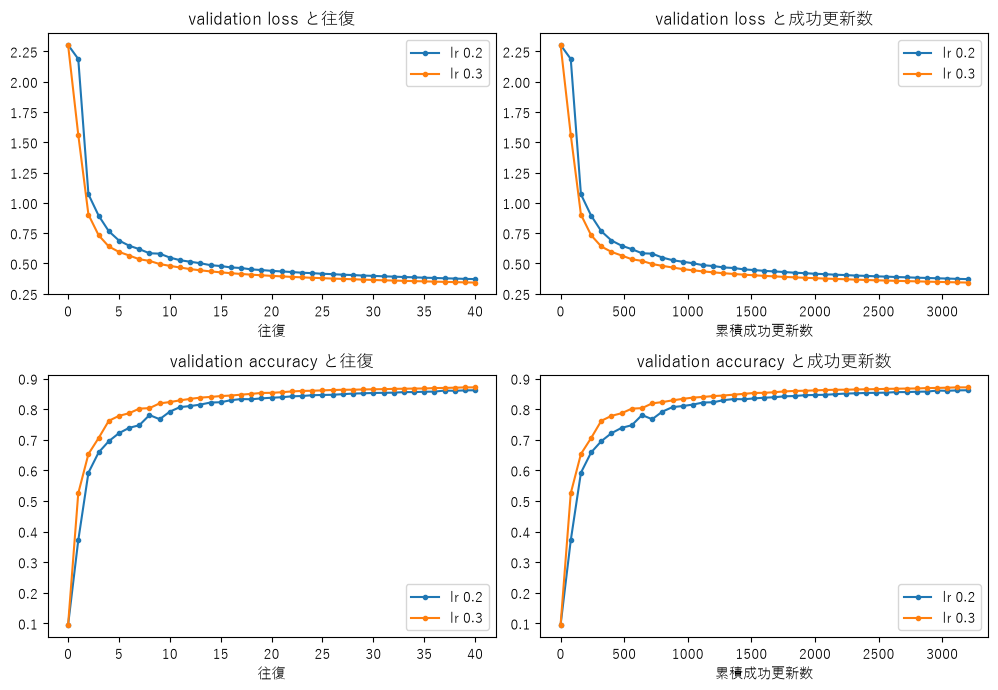

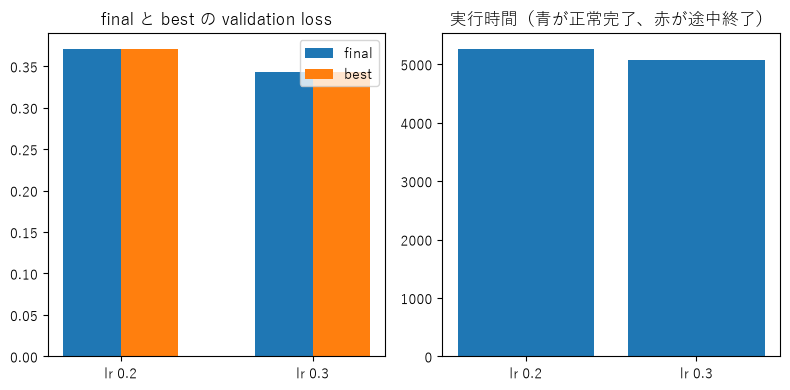

In [12]:
def assert_saved_main_condition(row):
    if row["status"] != "正常完了":
        return
    updates = int(float(row["successful_local_updates"]))
    if updates != 3200 or int(float(row["completed_sweeps"])) != MAX_SWEEPS:
        raise RuntimeError(
            f"{row['condition_id']} の正常完了は 40 往復・3,200 更新である必要があります: "
            f"sweeps={row['completed_sweeps']} updates={updates}"
        )
    history = read_history(models_dir / row["condition_id"] / "history.csv")
    if [int(item["sweep"]) for item in history] != list(range(MAX_SWEEPS + 1)):
        raise RuntimeError(f"{row['condition_id']} の履歴が 0 から 40 まで揃っていません。")
    if int(history[0]["cumulative_successful_updates"]) != 0:
        raise RuntimeError(f"{row['condition_id']} の初期更新数が 0 ではありません。")
    for previous, current in zip(history, history[1:]):
        delta = int(current["cumulative_successful_updates"]) - int(previous["cumulative_successful_updates"])
        if delta != 80:
            raise RuntimeError(
                f"{row['condition_id']} の往復 {int(current['sweep'])} の成功更新数が 80 ではありません: {delta}"
            )
        if int(current["center"]) != 0:
            raise RuntimeError(f"{row['condition_id']} の往復 {int(current['sweep'])} の中心が site 0 ではありません。")
    final_gap = abs(float(row["reloaded_final_validation_loss"]) - float(row["final_validation_loss"]))
    best_gap = abs(float(row["reloaded_best_validation_loss"]) - float(row["best_validation_loss"]))
    if final_gap > 1e-5 or best_gap > 1e-5:
        raise RuntimeError(f"{row['condition_id']} の再読込後指標が保存時の指標から離れています。")


def display_status(rows, expected_ids):
    found = {row["condition_id"]: row for row in rows}
    print("condition_id status completed_sweeps updates final_val best_val best_sweep seconds stop")
    for label in expected_ids:
        row = found.get(label)
        if row is None:
            print(label, "未実行")
            continue
        print(
            label,
            row["status"],
            row["completed_sweeps"],
            row["successful_local_updates"],
            row["final_validation_loss"],
            row["best_validation_loss"],
            row["best_sweep"],
            row["seconds_total"],
            row["stop_reason"],
        )


def print_histories(rows):
    for row in rows:
        history = read_history(models_dir / row["condition_id"] / "history.csv")
        print("history", row["condition_id"])
        print("sweep train_loss train_acc validation_loss validation_acc updates center")
        for item in history:
            print(
                int(item["sweep"]),
                item["train_loss"],
                item["train_acc"],
                item["validation_loss"],
                item["validation_acc"],
                int(item["cumulative_successful_updates"]),
                int(item["center"]),
            )


def print_reference_02():
    print("02 の参考: jointx100_s20_l4 は学習率 0.1、20往復、local step 4、更新 800 回。")
    print("03 の本実験は学習率 0.2 または 0.3、40往復、local step 8、更新 3,200 回。予算が違う。")
    if not REFERENCE_SUMMARY.is_file():
        print("02 の集計CSVが無いため、参考値は表示しません。")
        return
    with REFERENCE_SUMMARY.open(newline="", encoding="utf-8") as handle:
        reference_rows = list(csv.DictReader(handle))
    matched = [row for row in reference_rows if row["condition_id"] == "jointx100_s20_l4"]
    if len(matched) != 1:
        print("02 の集計に jointx100_s20_l4 が一意にありません。")
        return
    row = matched[0]
    print(
        row["condition_id"],
        "rate",
        row["tt_pair_learning_rate"],
        "sweeps",
        row["completed_sweeps"],
        "/",
        row["max_sweeps"],
        "local",
        row["local_steps_per_pair"],
        "updates",
        row["successful_local_updates"],
        "final_val",
        row["final_validation_loss"],
        row["final_validation_acc"],
        "best_sweep",
        row["best_sweep"],
        "seconds",
        row["seconds_total"],
        row["stop_reason"],
    )


print_reference_02()
if not main_rows:
    print("本実験2条件は未実行")
    print("smoke run は本実験の完了ではない。")
else:
    for row in main_rows:
        assert_saved_main_condition(row)
    display_status(main_rows, MAIN_CONDITION_IDS)
    print_histories(main_rows)
    figure, axes = plt.subplots(2, 2, figsize=(10, 7))
    for row in main_rows:
        history = read_history(models_dir / row["condition_id"] / "history.csv")
        label = f"lr {row['joint_learning_rate']}"
        axes[0, 0].plot(
            [item["sweep"] for item in history],
            [item["validation_loss"] for item in history],
            marker=".",
            label=label,
        )
        axes[0, 1].plot(
            [item["cumulative_successful_updates"] for item in history],
            [item["validation_loss"] for item in history],
            marker=".",
            label=label,
        )
        axes[1, 0].plot(
            [item["sweep"] for item in history],
            [item["validation_acc"] for item in history],
            marker=".",
            label=label,
        )
        axes[1, 1].plot(
            [item["cumulative_successful_updates"] for item in history],
            [item["validation_acc"] for item in history],
            marker=".",
            label=label,
        )
    axes[0, 0].set_title("validation loss と往復")
    axes[0, 1].set_title("validation loss と成功更新数")
    axes[1, 0].set_title("validation accuracy と往復")
    axes[1, 1].set_title("validation accuracy と成功更新数")
    axes[0, 0].set_xlabel("往復")
    axes[1, 0].set_xlabel("往復")
    axes[0, 1].set_xlabel("累積成功更新数")
    axes[1, 1].set_xlabel("累積成功更新数")
    for axis in axes.ravel():
        axis.legend()
    figure.tight_layout()
    figure.savefig(results_dir / "curves_lr0p2_lr0p3.png", dpi=120)
    plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(8, 4))
    positions = list(range(len(main_rows)))
    labels = [f"lr {row['joint_learning_rate']}" for row in main_rows]
    axes[0].bar(
        [position - 0.15 for position in positions],
        [float(row["final_validation_loss"]) for row in main_rows],
        width=0.3,
        label="final",
    )
    axes[0].bar(
        [position + 0.15 for position in positions],
        [float(row["best_validation_loss"]) for row in main_rows],
        width=0.3,
        label="best",
    )
    axes[0].set_xticks(positions)
    axes[0].set_xticklabels(labels)
    axes[0].set_title("final と best の validation loss")
    axes[0].legend()
    colors = ["C0" if row["status"] == "正常完了" else "C3" for row in main_rows]
    axes[1].bar(positions, [float(row["seconds_total"]) for row in main_rows], color=colors)
    axes[1].set_xticks(positions)
    axes[1].set_xticklabels(labels)
    axes[1].set_title("実行時間（青が正常完了、赤が途中終了）")
    figure.tight_layout()
    figure.savefig(results_dir / "final_best_and_time.png", dpi=120)
    plt.show()


## 7. 結果の読み方と、本実験を始める手順

0.2 と 0.3 は、同じ初期 checkpoint、同じ 40 往復、同じ local step 8 で比べる。final を主に見て、best は別に見る。往復が多いほど best の候補は増える。改善があっても、TT 更新だけの効果ではない。二つの学習率は条件の中では同じ値に揃えている。

本実験を開始する手順は次である。

1. smoke の終了理由、有限性、相対更新量、時間見積もりを確認する。1往復の有限性は、40往復の安定性ではない。
2. 設定セルの `RUN_MAIN_EXPERIMENT` を `True` にする。`RUN_SMOKE` は `False` のままでよい。
3. データ読込から下を実行する。各条件は `initial_stage_c.pt` から作り直される。途中で止まった場合は、同じスイッチのまま再実行すると、集計済みの条件を確認して続きから実行する。
4. 00、01、02、および `initial_stage_c.pt` は変更しない。

履歴は `models/40_dmrg/10_fashion_mnist_mlp/03_joint_learning_rate_02_03_s40_l8/<条件ID>/history.csv`、局所ログは同じディレクトリの `local_updates.csv` にある。局所ログには相対更新量、保持 rank、更新後の中心が入る。一覧は `results/40_dmrg/10_fashion_mnist_mlp/03_joint_learning_rate_02_03_s40_l8/condition_summary.csv` である。smoke は末尾が `_smoke` のディレクトリにある。
